In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

# Single Run

In [ ]:

algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=int(50), strategy1='AC', strategy2='AC', verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 50)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

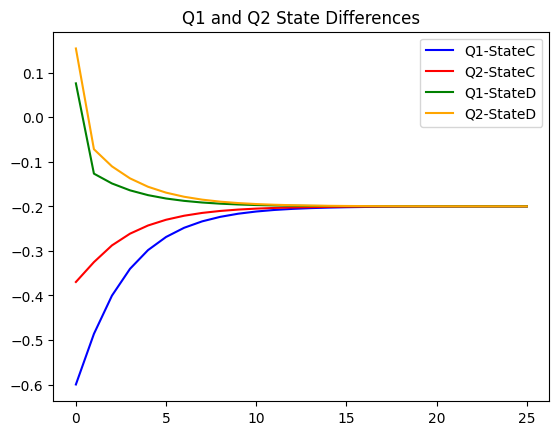

In [ ]:
internal_debug = True
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.title('Q1 and Q2 State Differences')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [ ]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


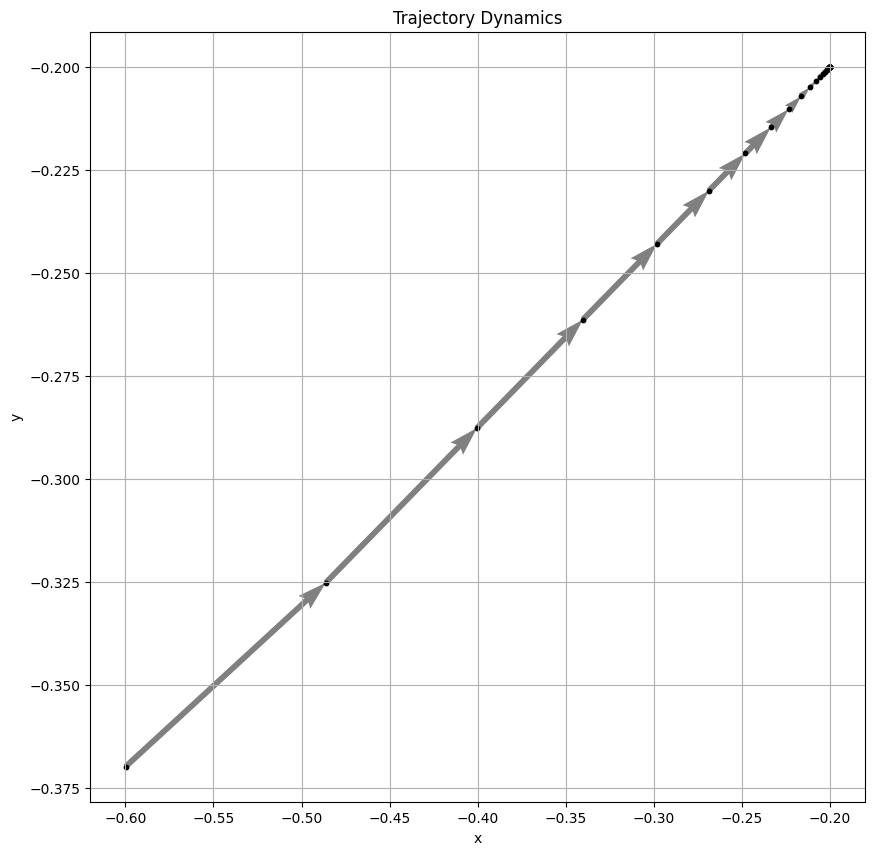

In [ ]:
trajectory_dynamics_plot(x, y)

In [ ]:
plotter = VectorFieldAutomatic(
        q1=q1, q2=q2,
        t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
        func1=func1,
        func2=func2,
        alpha=alpha,
        show_trajectory=True,
        show_basin=True
    )
plotter.plot()

# CASE BY CASE STUDY

In [3]:
#TODO: only look at the particular quadrant based on the mathematica conditions


Running pair: (AD, AD)


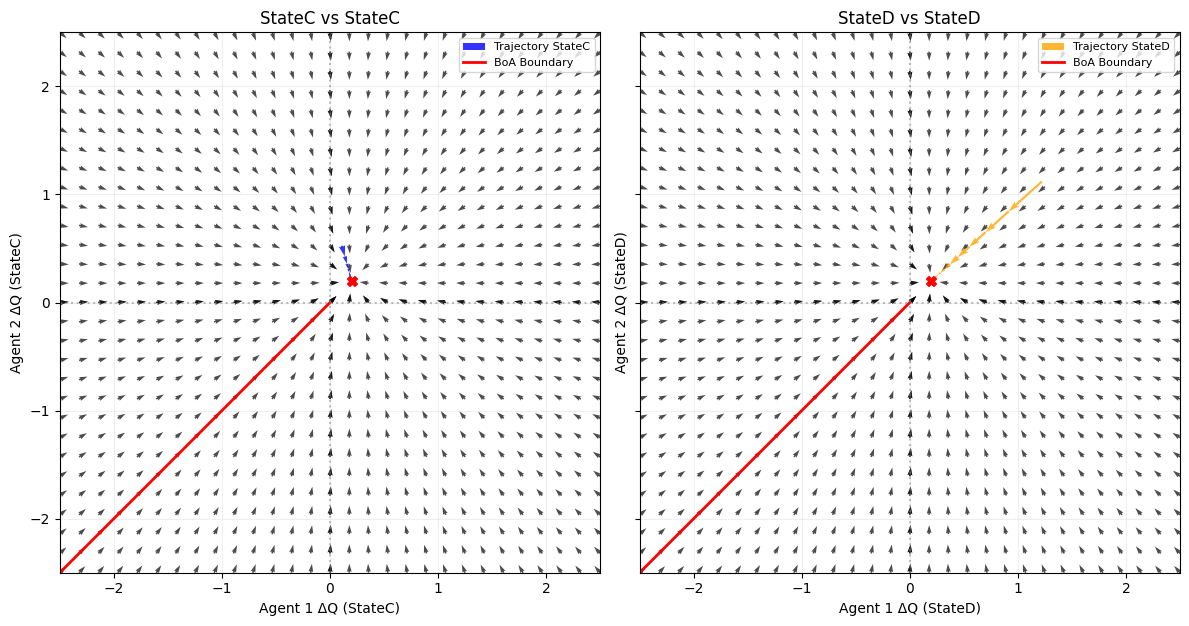

Running pair: (AD, GT)


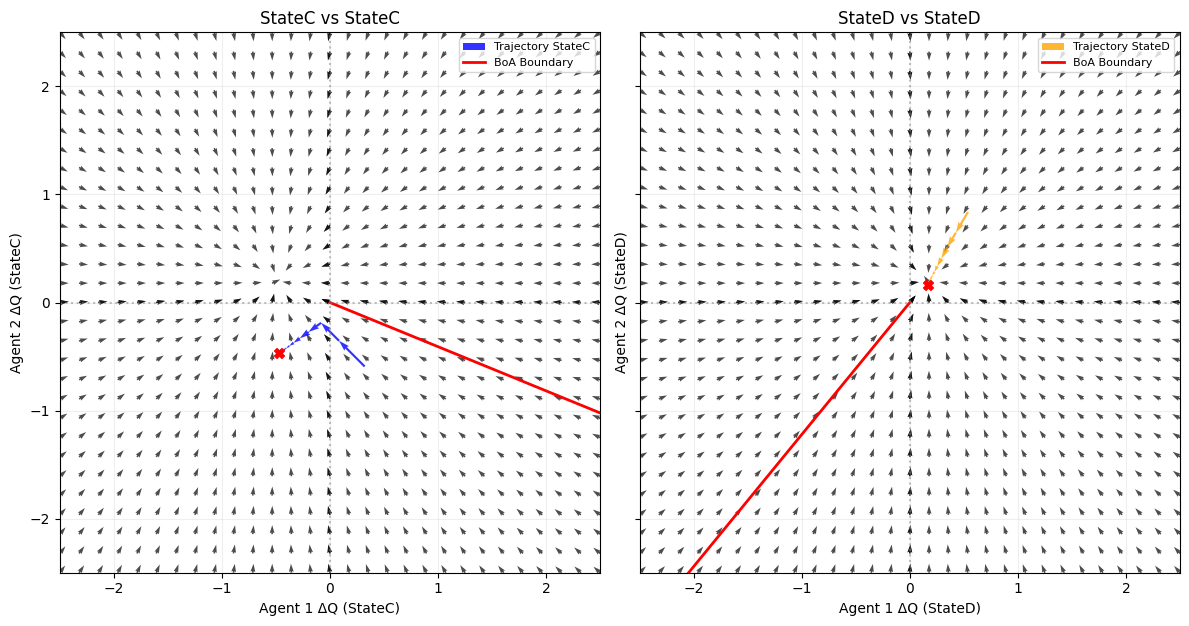

Running pair: (AD, AGT)


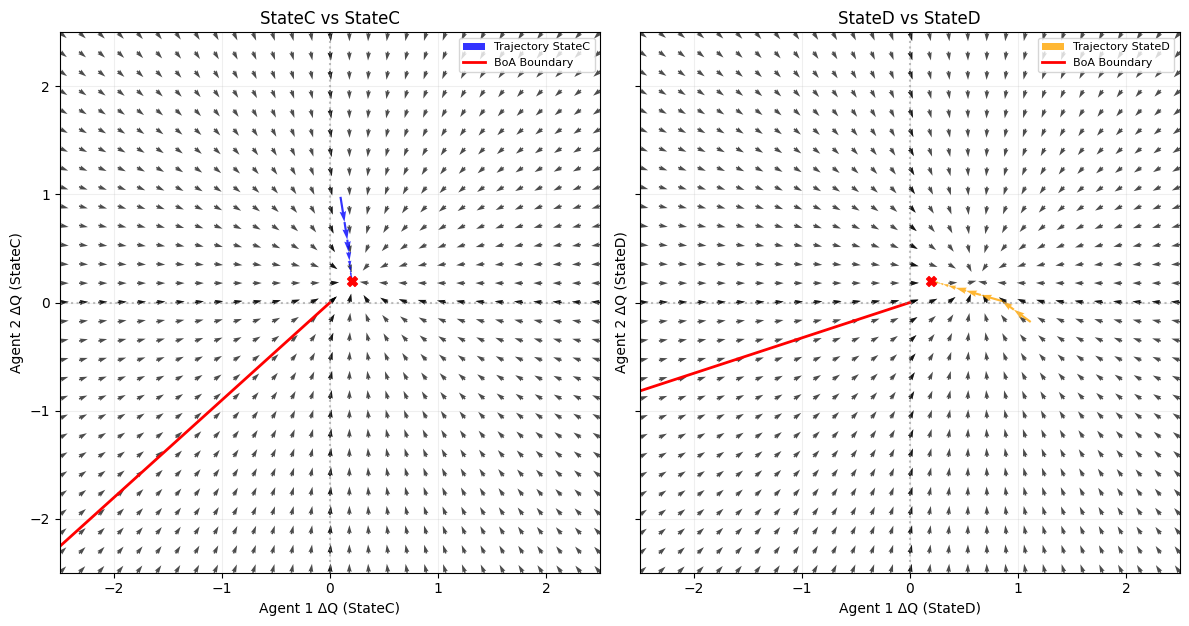

Running pair: (AD, AC)


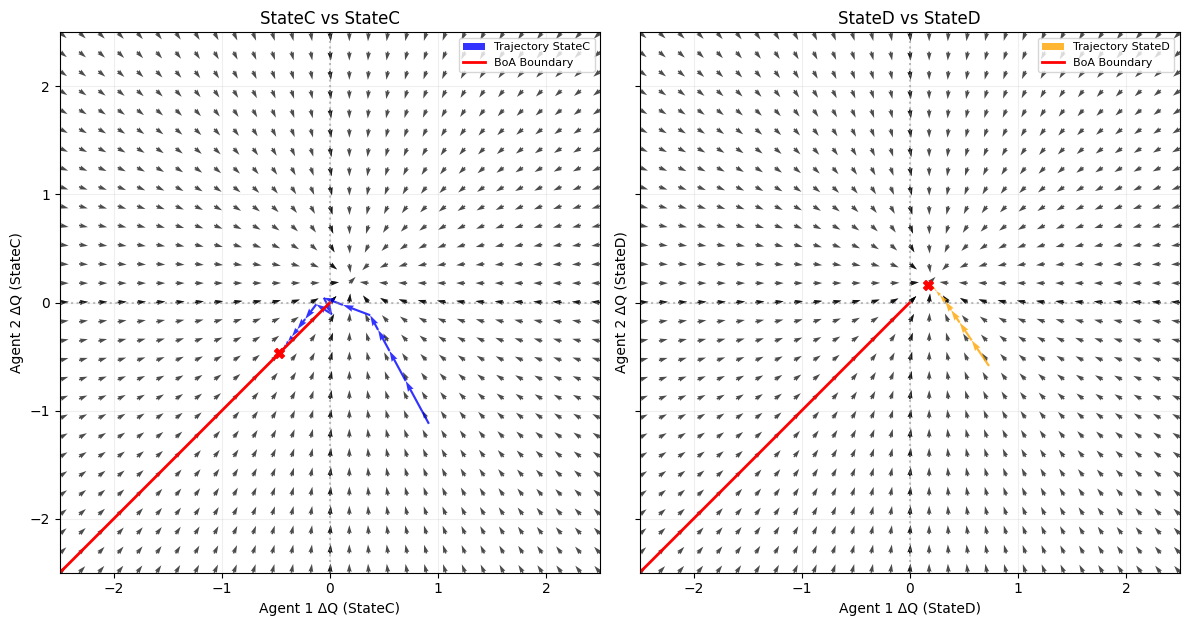

Running pair: (GT, AD)


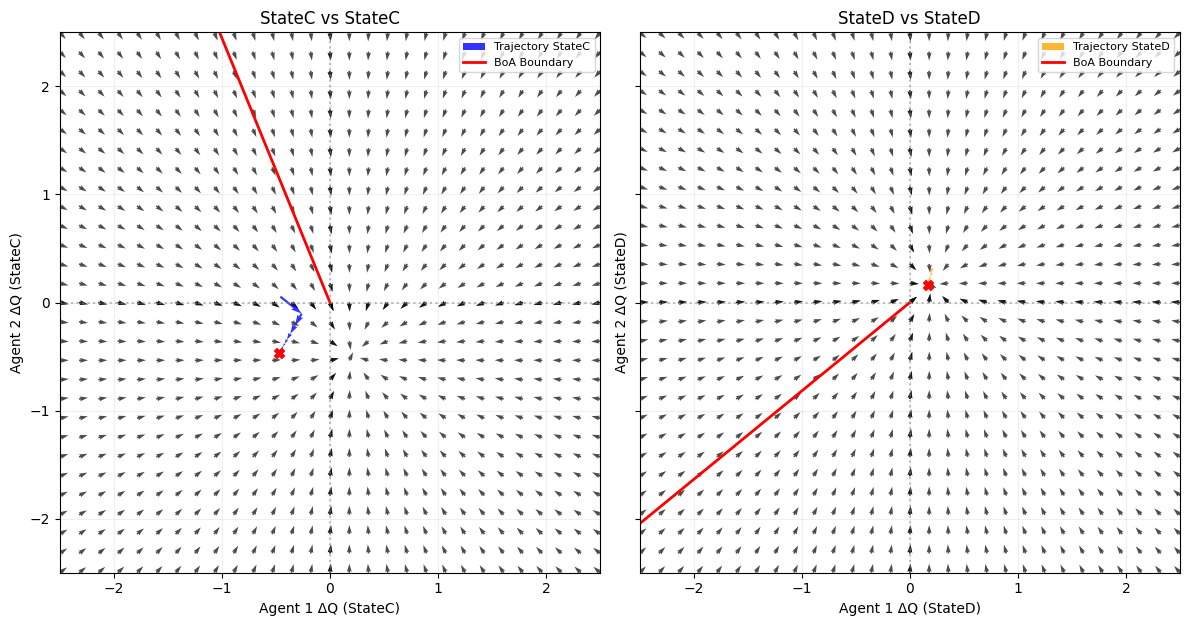

Running pair: (GT, GT)


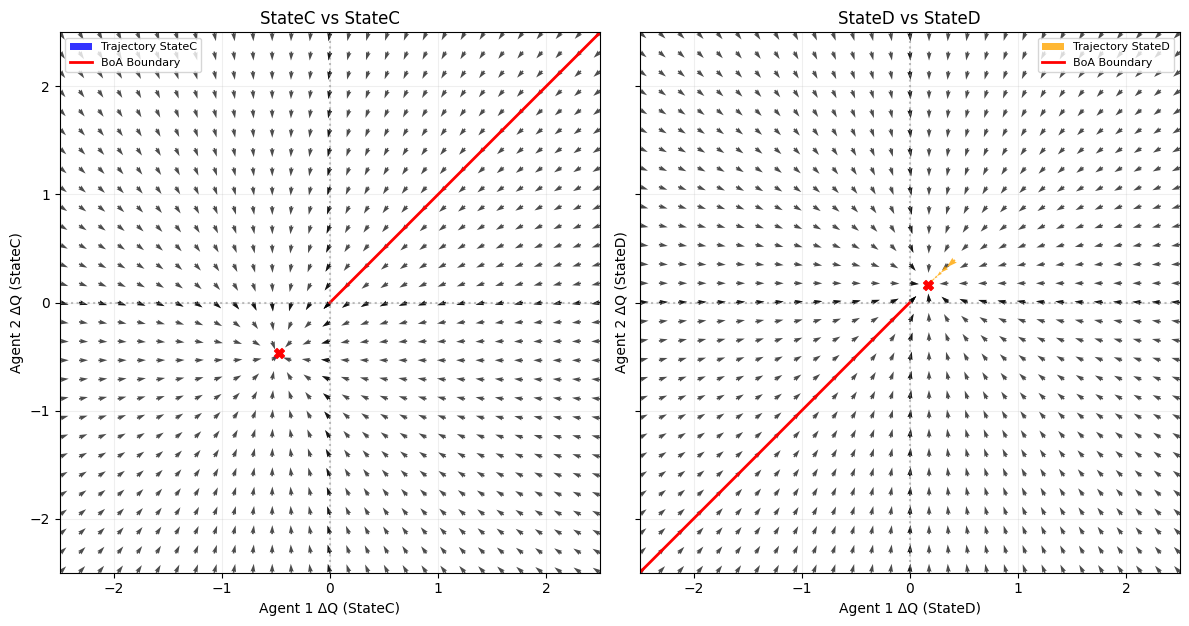

Running pair: (GT, AGT)


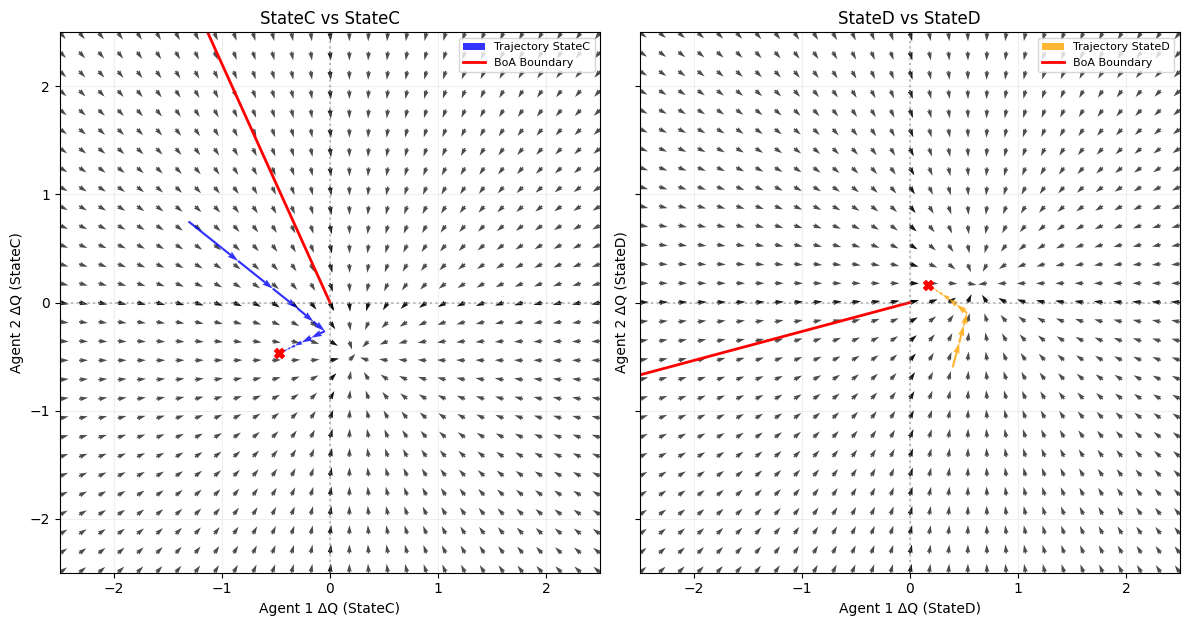

Running pair: (GT, AC)


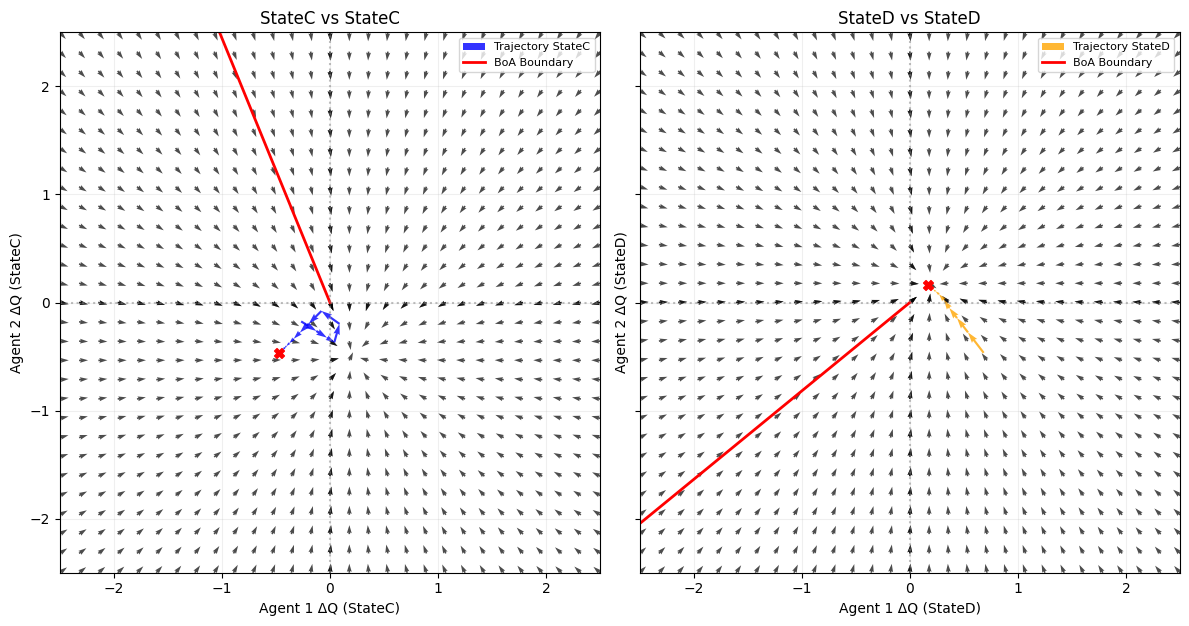

Running pair: (AGT, AD)


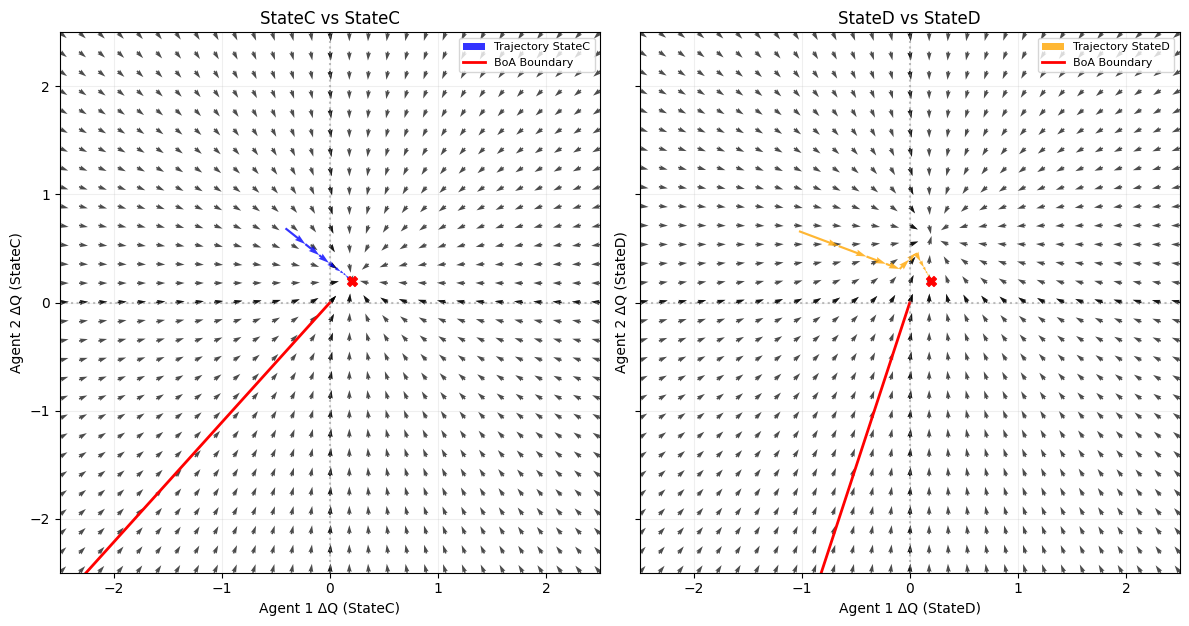

Running pair: (AGT, GT)


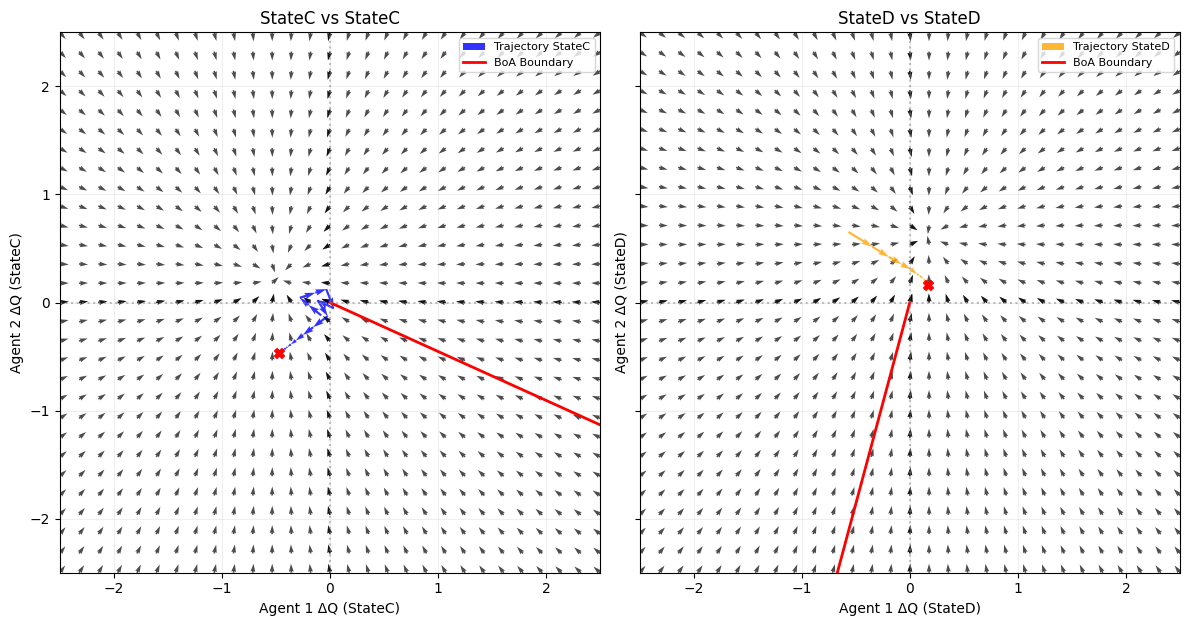

Running pair: (AGT, AGT)


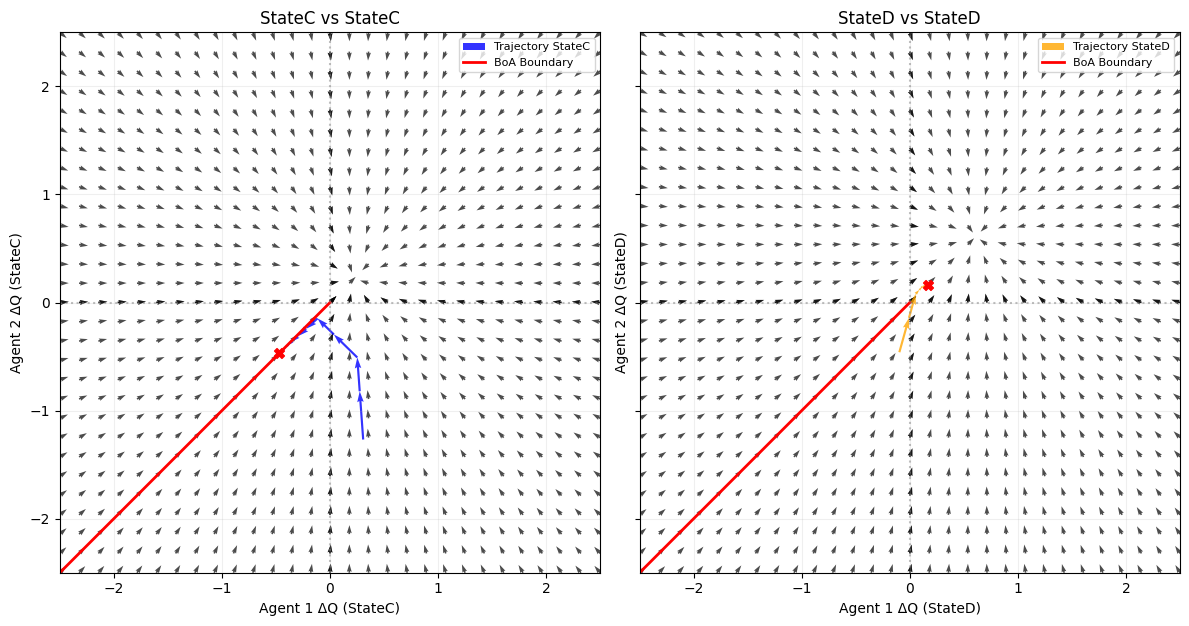

Running pair: (AGT, AC)


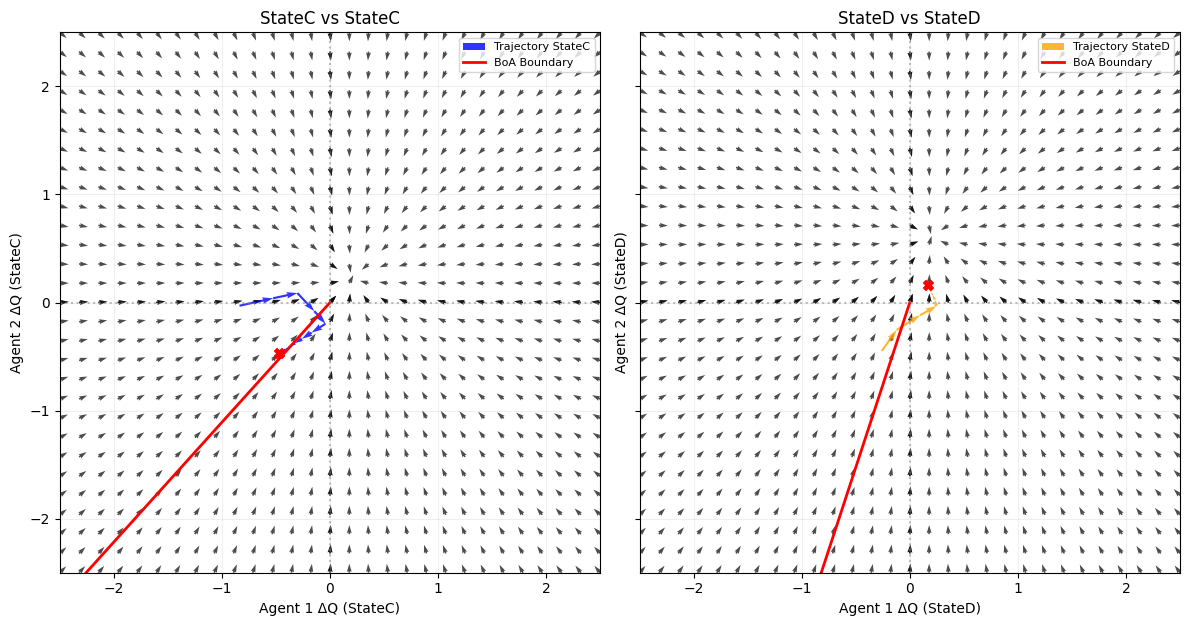

Running pair: (AC, AD)


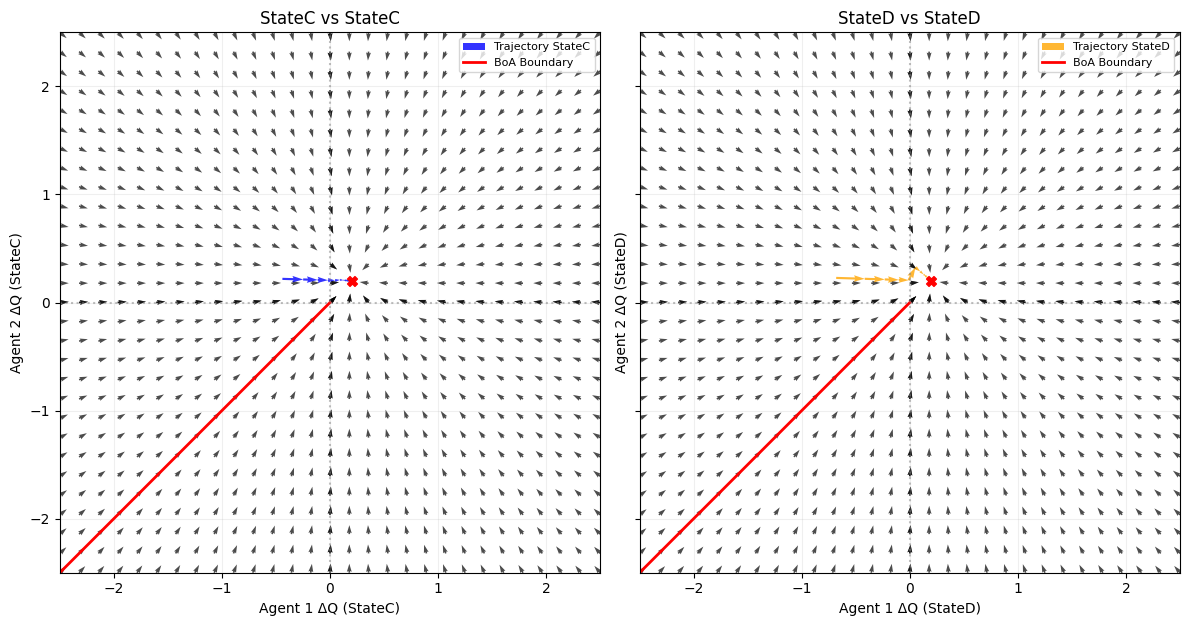

Running pair: (AC, GT)


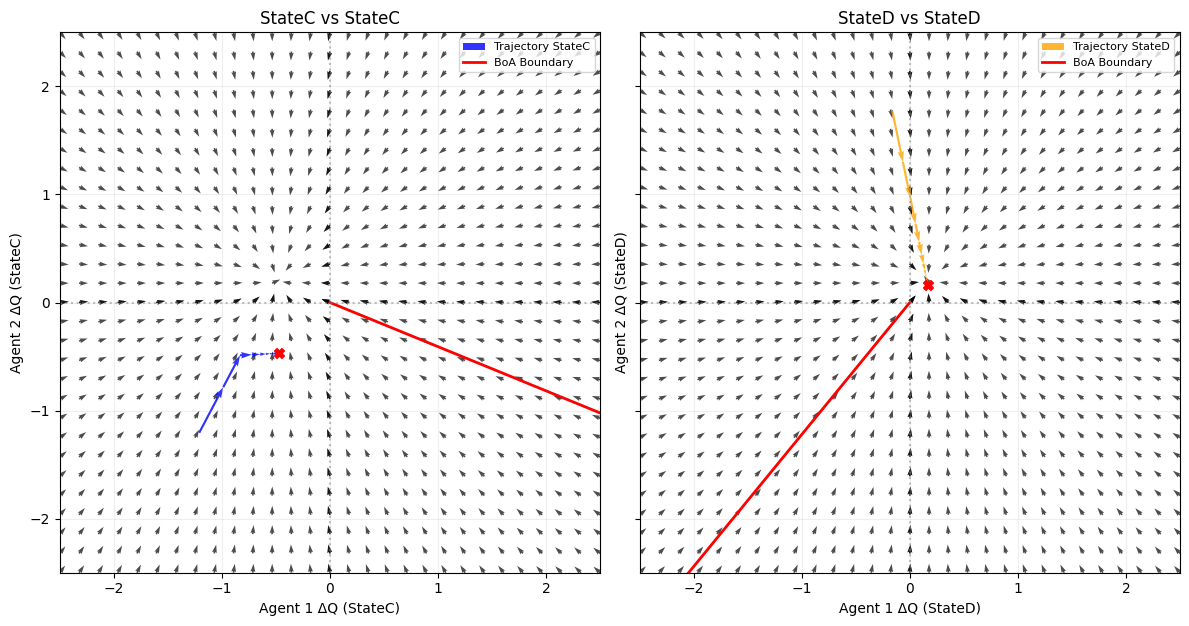

Running pair: (AC, AGT)


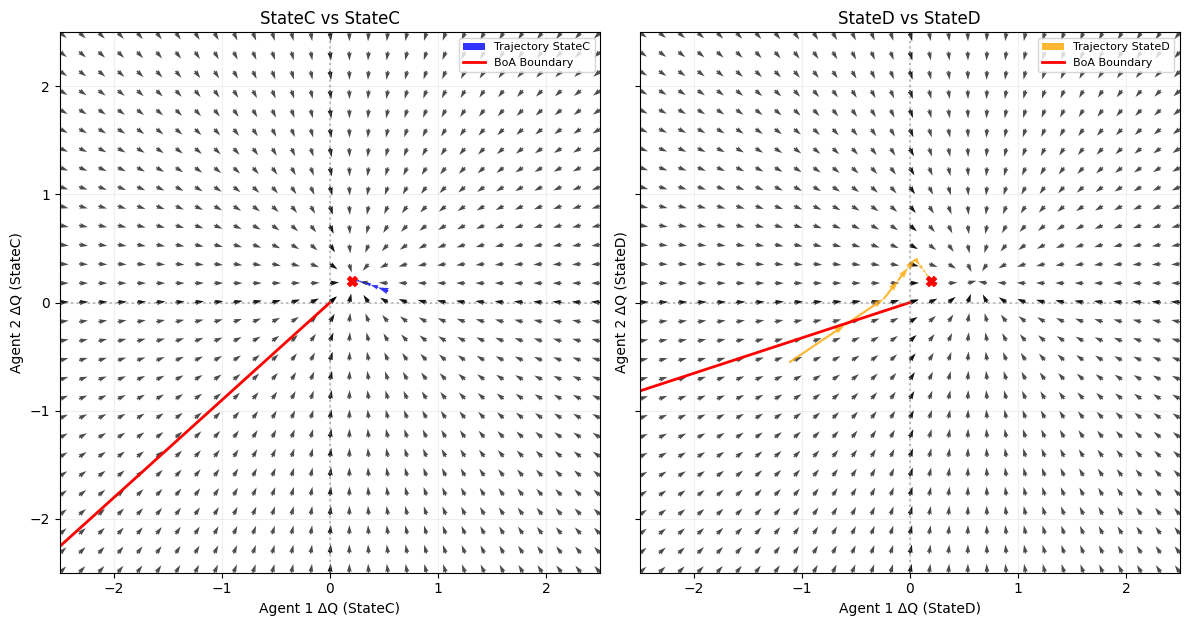

Running pair: (AC, AC)


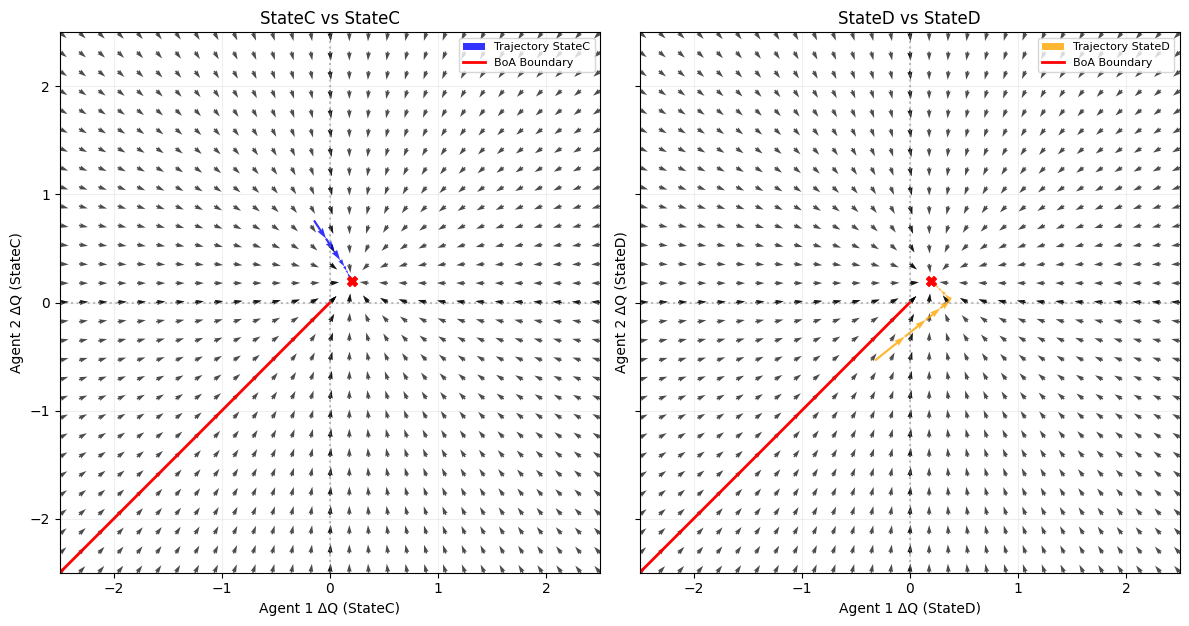

In [4]:
# Strategy pairs
strategy_pairs = [
    ("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    ("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    ("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    ("AC","AD"), ("AC","GT"), ("AC","AGT"), ("AC","AC")
]

# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}

for s1, s2 in strategy_pairs:
    print(f"Running pair: ({s1}, {s2})")

    # Initialize algorithm with fixed strategy pair
    algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=50, strategy1=s1, strategy2=s2, verbose=False
    )

    # Run the algorithm
    q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

    # Pick a sample
    exp = np.random.randint(0, 50)
    q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
    q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]

    # Select functions for vector field based on opponent strategy
    func1 = func_map[s2]  # x-component uses opponent strategy s2
    func2 = func_map[s1]  # y-component uses same opponent strategy

    # Plot vector field
    plotter = VectorFieldAutomatic(
        q1=q1, q2=q2,
        t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
        func1=func1,
        func2=func2,
        alpha=alpha,
        show_trajectory=True,
        show_basin=True
    )
    plotter.plot()


#AD-AD: there is not a basin of attraction boundary


In [5]:
x_bounds

NameError: name 'x_bounds' is not defined